# **Object Detection (Drone, Bird, Aircraft) with AlexNet**



*Author: Shreya Sengupta*

*Co-Author: Subhranil Dey*

*Industrial Internship under the guidance of Atul Rawat Sir, at CDAC Center in North East (CINE), Silchar.*



 1. Introduction:

Object detection is a fundamental task in computer vision that involves identifying and localizing objects within an image. Accurate object detection plays a crucial role in various applications, such as autonomous vehicles, surveillance, and image-based search engines. In this project, we explore the implementation of object detection using the well-known AlexNet model, a deep convolutional neural network.

The objective of this project is to build an object detection model that can classify images into three classes: "Drone," "Bird," and "Aircrafts." Additionally, the model will predict bounding box coordinates for each detected object, allowing for precise localization.

2. Methodology:

AlexNet Model:
The AlexNet architecture consists of several convolutional layers, ReLU activation functions, and max-pooling layers. The model is designed to learn hierarchical features from images, which are then used for classification. Additionally, we extend the architecture with a bounding box regressor to predict object coordinates.

Custom Dataset:
We create a custom dataset using images and corresponding annotations stored in a CSV file. The dataset is designed to facilitate both object classification and object detection tasks. Each image is associated with a class label ("Drone", "Bird," or "Aircrafts") and bounding box coordinates.

Data Preprocessing:
To ensure uniformity and better convergence during training, we preprocess the images. The transformation pipeline includes resizing the images to (227, 227) pixels, converting them to tensors, and normalizing pixel values.

Loss Functions and Optimizer:
For classification, we employ the CrossEntropyLoss, while the SmoothL1Loss is used for bounding box regression. The Adam optimizer is chosen for optimization.

3. Experiment Setup:

The project was implemented using Google Colab, which provides a powerful GPU for accelerated deep learning computations. The key specifications of the experiment setup are as follows:

Hardware: Google Colab GPU (NVIDIA Tesla K80 12GB)
Software: Python 3.7, PyTorch 1.9, TorchVision 0.10, NumPy 1.19

4. Training and Evaluation:

The model can be trained in two ways. We can perform training for a fixed number of epochs without saving the model after each epoch. During training, we recorded the average class loss, bounding box loss, and class accuracy per epoch.

Or, the training was extended with a validation phase. After each epoch, the model's performance was evaluated on the validation set, and the model's state was saved if the validation accuracy improved.

The following parameters are set for training
No. of Epochs: [55]
Batch Size: [32]
Learning Rate: [0.001]
Step Size for LR Scheduler: [0.1]
Gamma for LR Scheduler: [10]

5. Results:

The trained model achieved promising results in both object classification and bounding box regression tasks. The model exhibited considerable accuracy in distinguishing between "Drone," "Bird," and "Aircrafts" classes. Additionally, the bounding box regressor successfully localized the detected objects.

6. Object Detection on Test Images:

For testing the object detection capabilities, first we tried on few images from the training set, then we used a set of real-world images downloaded from Google which are different from the training set. The model accurately predicted the class labels and displayed the corresponding bounding boxes around the detected objects.

7. Conclusion:

In conclusion, this project demonstrates the successful implementation of object detection using the AlexNet model in PyTorch. The model showcased impressive performance in classifying and localizing objects within images. The project's outcome underscores the significance of deep learning models in advancing computer vision tasks and holds promise for practical applications in various domains. Future work could focus on exploring more complex architectures and larger datasets to further enhance object detection accuracy and generalization.

The complete code is given below.

#Importing required libraries and mounting Google Drive

In [ ]:
#Importing Required Libraries: The code begins by importing the necessary
# Python libraries such as PyTorch, TorchVision, NumPy, pandas, Matplotlib, and others.

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


The imported libraries are needed for various tasks throughout the code. Let's go through each import statement and understand the purpose of each library:

1. torch, torch.nn, torch.optim, torchvision.transforms: These libraries are part of PyTorch, a popular deep learning framework. They provide functionalities for building and training neural networks, defining loss functions, optimization algorithms, and data transformations.

2. PIL.Image: This library is part of the Python Imaging Library (PIL) and is used for handling image data.

3. torch.utils.data.Dataset, torch.utils.data.DataLoader: These classes are part of PyTorch and are used for creating custom datasets and data loaders to efficiently load data during training and evaluation.

4. matplotlib.pyplot, matplotlib.patches: These libraries are used for plotting and visualizing images with bounding boxes and labels.

5. os, pandas, numpy: These libraries provide functionalities for operating system-related tasks, handling data in tabular form (e.g., CSV files), and numerical computations.

6. sklearn.metrics: This library contains various metrics for evaluating machine learning models, such as confusion matrix, precision, and recall.

7. google.colab.drive: This module is specific to Google Colab, and it is used to mount the Google Drive so that the dataset and model files can be accessed from Google Drive storage.

These libraries are essential for tasks such as defining and training the AlexNet model, creating a custom dataset for object detection, loading and preprocessing data, calculating loss functions and optimization, and visualizing the results of object detection on test images.


#Creating AlexNet model layer by layer

In [ ]:
# Defining the AlexNet Model:

class AlexNet(nn.Module):
    def __init__(self, num_classes=3):
        super(AlexNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )
        self.bbox_regressor = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, 4),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        classes = self.classifier(x)
        bbox=self.bbox_regressor(x)
        return classes,bbox



The code defines a custom implementation of the
 AlexNet deep learning architecture using PyTorch's nn.Module class. The model
  consists of several convolutional layers, ReLU activation functions,
  max-pooling layers, and fully connected layers. It also includes a bounding
  box regressor, in addition to the regular classification layers, for object
  detection purposes.

In the line super(AlexNet, self).__init__(), super is a built-in Python function used for calling methods of a parent class. In this context, it is used to call the constructor (__init__ method) of the parent class of AlexNet.
Using super() allows you to access the methods and attributes of the parent class from the child class. In the case of AlexNet, it is a subclass of nn.Module (the superclass), which is a base class for all PyTorch neural network modules.
Here's what each part of the line means:

super(AlexNet, self): The super() function takes two arguments. The first argument is the class (AlexNet in this case), and the second argument is the instance of that class (self is the current instance of AlexNet). It returns a temporary object of the superclass, which can be used to call the methods of the superclass.

.__init__(): This calls the constructor (__init__ method) of the superclass (nn.Module). It initializes the inherited attributes and behaviors of the superclass.

By calling super(AlexNet, self).__init__(), you ensure that the initialization logic defined in the superclass (nn.Module) is executed before any custom initialization code in the __init__ method of AlexNet. This is important to properly set up the model and its required components before adding any custom layers or behaviors specific to AlexNet.



In the code, **self.features = nn.Sequential(...)** is used to define the feature extraction part of the AlexNet model. It creates a sequence of layers (a neural network module) that will be used to process the input images and extract meaningful features from them.

The nn.Sequential class in PyTorch is a container that allows you to stack multiple layers sequentially. When you pass a sequence of layers to nn.Sequential, it executes each layer one after another in the order they are provided.

Here's the breakdown of the layers defined within self.features:

1. nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2): This is the first convolutional layer. It takes 3 input channels (for RGB images), applies 96 filters of size 11x11, uses a stride of 4 (moves the filter by 4 pixels at a time), and adds padding of size 2 to maintain the spatial dimensions.

nn.ReLU(inplace=True): This is a rectified linear unit (ReLU) activation function. It introduces non-linearity into the model by setting all negative values to zero ("in-place" means it modifies the input directly without using additional memory).

nn.MaxPool2d(kernel_size=3, stride=2): This is a max-pooling layer. It performs 2x2 max-pooling with a stride of 2, reducing the spatial dimensions of the feature maps.

2. nn.Conv2d(96, 256, kernel_size=5, padding=2): This is the second convolutional layer. It takes 96 input channels (output from the previous layer), applies 256 filters of size 5x5, and adds padding of size 2.

nn.ReLU(inplace=True): Another ReLU activation function.

nn.MaxPool2d(kernel_size=3, stride=2): Another max-pooling layer.

3. nn.Conv2d(256, 384, kernel_size=3, padding=1): This is the third convolutional layer. It takes 256 input channels, applies 384 filters of size 3x3, and adds padding of size 1.

nn.ReLU(inplace=True): Another ReLU activation function.

4. nn.Conv2d(384, 384, kernel_size=3, padding=1): This is the fourth convolutional layer. It takes 384 input channels, applies 384 filters of size 3x3, and adds padding of size 1.

nn.ReLU(inplace=True): Another ReLU activation function.

5. nn.Conv2d(384, 256, kernel_size=3, padding=1): This is the fifth convolutional layer. It takes 384 input channels, applies 256 filters of size 3x3, and adds padding of size 1.

nn.ReLU(inplace=True): Another ReLU activation function.

nn.MaxPool2d(kernel_size=3, stride=2): Another max-pooling layer.

Together, these layers form the feature extraction part of the AlexNet model. The convolutional layers and activation functions are responsible for capturing hierarchical and abstract features from the input images, and the max-pooling layers help reduce the spatial dimensions, making the computation more efficient. The output of this feature extraction part will then be passed to the fully connected layers for classification and bounding box regression.




```python
self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )
```
This code defines the classification head of the AlexNet model. It takes the output from the feature extraction part (stored in `self.features`) and further processes it to perform object classification based on the features extracted from the input images.

Let's go through each part of the code:

1. `self.avgpool = nn.AdaptiveAvgPool2d((6, 6))`: This line defines the adaptive average pooling layer. It takes the output from the feature extraction part and applies adaptive average pooling to convert the feature maps into a fixed-size representation of 6x6. Adaptive average pooling allows the model to handle input images of different sizes and still produce a consistent-sized output for classification.

2. `self.classifier = nn.Sequential(...)`: This defines the classifier part of the AlexNet model. It is implemented as a sequential neural network module and consists of several layers.

    - `nn.Dropout()`: Dropout is applied to regularize the model and prevent overfitting during training. It randomly sets some neuron outputs to zero, forcing the model to rely on different features for classification during each training iteration.

    - `nn.Linear(256 * 6 * 6, 4096)`: This is a fully connected layer that takes the flattened output of the adaptive average pooling layer (with a size of 256 * 6 * 6) and projects it to a 4096-dimensional space.

    - `nn.ReLU(inplace=True)`: Another ReLU activation function. It introduces non-linearity after the first fully connected layer.

    - `nn.Dropout()`: Another dropout layer for regularization.

    - `nn.Linear(4096, 4096)`: Another fully connected layer that reduces the 4096-dimensional representation to another 4096-dimensional space.

    - `nn.ReLU(inplace=True)`: Another ReLU activation function.

    - `nn.Linear(4096, num_classes)`: The final fully connected layer that maps the 4096-dimensional representation to the number of output classes (`num_classes`). In this case, `num_classes` is set to 3, representing the classes "Drone", "Bird", and "Aircrafts" for the object classification task.

After passing the input images through the feature extraction part (`self.features`), the output is passed through the adaptive average pooling layer (`self.avgpool`), which generates a fixed-size representation. Then, this representation is flattened and passed through the classifier (`self.classifier`) to perform the final classification of the objects present in the images. The model predicts the class label with the highest probability as the object class and uses the softmax function internally to convert raw scores into probabilities.

```python
self.bbox_regressor = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Linear(4096, 4),
        )
```
This part of the code defines the bounding box regressor for the object detection task in the AlexNet model.

The objective of the bounding box regressor is to predict the coordinates of the bounding box that tightly surrounds the detected object in the input image. The bounding box is represented by four values: `xmin`, `ymin`, `width`, and `height`. The values of `xmin` and `ymin` represent the coordinates of the top-left corner of the bounding box, while `width` and `height` represent the width and height of the bounding box, respectively.

Let's break down the code:

1. `self.bbox_regressor = nn.Sequential(...)`: This line defines the bounding box regressor as a sequential neural network module. Similar to the classifier, the bounding box regressor consists of several fully connected layers and activation functions.

2. `nn.Linear(256 * 6 * 6, 4096)`: This is the first fully connected layer that takes the flattened output of the adaptive average pooling layer (`self.avgpool`). The size of the input to this layer is `256 * 6 * 6` because the adaptive average pooling layer produces a fixed-size representation of 6x6 with 256 channels.

3. `nn.ReLU(inplace=True)`: A ReLU activation function that introduces non-linearity after the first fully connected layer.

4. `nn.Linear(4096, 4096)`: This is the second fully connected layer that maps the 4096-dimensional representation to another 4096-dimensional space.

5. `nn.ReLU(inplace=True)`: Another ReLU activation function.

6. `nn.Linear(4096, 4)`: The final fully connected layer that maps the 4096-dimensional representation to 4 output values representing the bounding box coordinates (`xmin`, `ymin`, `width`, `height`).

The purpose of this bounding box regressor is to learn to predict the bounding box coordinates based on the features extracted from the input image by the feature extraction part (`self.features`). The predicted bounding box coordinates will be used to localize the detected object accurately within the image during the object detection task.

During training, the model is jointly optimized to minimize the classification loss (using cross-entropy loss) and the bounding box regression loss (using smooth L1 loss). By training both the classification head and bounding box regressor together, the model learns to perform object detection effectively, identifying the class label of the object and accurately predicting its bounding box coordinates.



**def forward(self, x):**
The `forward` method in the `AlexNet` class defines the forward pass of the AlexNet model. It describes how the input data flows through the various layers of the model to produce the final output. The forward pass is a fundamental step in training and using the model for inference.

Here's what each line in the `forward` method does:

1. `x = self.features(x)`: The input tensor `x`, representing the input image, is passed through the feature extraction part of the model (`self.features`). This part includes a sequence of convolutional layers, ReLU activations, and max-pooling layers, which extract hierarchical features from the input image.

2. `x = self.avgpool(x)`: The output from the feature extraction part is passed through an adaptive average pooling layer (`self.avgpool`). This layer converts the feature maps into a fixed-size representation of 6x6, regardless of the input image's size. Adaptive average pooling ensures that the model can handle images of varying resolutions.

3. `x = torch.flatten(x, 1)`: The output from the adaptive average pooling layer is flattened into a 1-dimensional tensor. This step is necessary because the classification and bounding box regression heads expect a 1-dimensional input.

4. `classes = self.classifier(x)`: The flattened tensor is passed through the classifier part of the model (`self.classifier`). This part consists of fully connected layers and activation functions responsible for predicting the object class probabilities. The output `classes` will contain the predicted class probabilities for each class (in this case, three classes: "Drone", "Bird", and "Aircrafts").

5. `bbox = self.bbox_regressor(x)`: The same flattened tensor is passed through the bounding box regressor (`self.bbox_regressor`). This part consists of fully connected layers and activation functions responsible for predicting the bounding box coordinates (`xmin`, `ymin`, `width`, `height`) for object detection.

6. `return classes, bbox`: The method returns two outputs: `classes`, which contains the predicted class probabilities, and `bbox`, which contains the predicted bounding box coordinates. These outputs will be used during training to calculate the classification loss and bounding box regression loss and during inference to obtain the final object detection results.

In summary, the `forward` method defines the flow of data through the AlexNet model. It takes the input image, passes it through the feature extraction part, performs adaptive average pooling to obtain a fixed-size representation, flattens the output, and then passes it through the classifier and bounding box regressor to predict the object class probabilities and bounding box coordinates for object detection.

# Creating a custom dataset class

In [ ]:
# Define a custom dataset class


class CustomDataset(Dataset):
    def __init__(self, folder_path, annotations_file, transform=None):
        self.data = pd.read_csv(annotations_file)
        self.folder_path = folder_path
        self.transform = transform

        # Create a label encoding dictionary
        self.label_dict = {'Drone': 0, 'Bird': 1, 'Aircrafts': 2}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        img_path = os.path.join(self.folder_path, self.data.iloc[index, 0])
        image = Image.open(img_path).convert('RGB')
        label = self.data.iloc[index, 1]  # Get the class label

        # Encode the label using the label encoding dictionary
        label = self.label_dict[label]

        xmin=self.data.iloc[index,2]
        ymin=self.data.iloc[index,3]
        xmax=self.data.iloc[index,4]
        ymax=self.data.iloc[index,5]

        bbox_coords=torch.tensor([xmin,
                                  ymin,
                                  xmax-xmin,
                                  ymax-ymin])

        if self.transform is not None:
            image = self.transform(image)

        return image, label, bbox_coords


The code defines a custom dataset class named CustomDataset that extends the
Dataset class from PyTorch. It loads images from the specified folder path and
their corresponding annotations from a CSV file. The dataset is designed for
object classification and object detection tasks.

Let's go through the class `CustomDataset` line by line:

```python
class CustomDataset(Dataset):
```

- This line defines a new class named `CustomDataset` that inherits from the `Dataset` class provided by PyTorch. By inheriting from `Dataset`, `CustomDataset` gains access to important functionalities and behaviors required to work with datasets in PyTorch.

```python
    def __init__(self, folder_path, annotations_file, transform=None):
```

- The `__init__` method is a special method that serves as the constructor for the class. It is called when an instance of `CustomDataset` is created.

- This method takes three parameters: `folder_path`, `annotations_file`, and `transform`. These parameters represent the necessary information to load and process the data for the custom dataset.

```python
        self.data = pd.read_csv(annotations_file)
```

- `self.data` is an attribute of the `CustomDataset` class. It is used to store the dataset annotations loaded from the CSV file specified by `annotations_file`.

- `pd.read_csv(annotations_file)` reads the CSV file and loads its content into a pandas DataFrame. This DataFrame will contain information about image filenames, corresponding class labels, and bounding box coordinates for each image in the dataset.

```python
        self.folder_path = folder_path
```

- `self.folder_path` is another attribute of the `CustomDataset` class. It stores the path to the folder where the dataset images are located.

```python
        self.transform = transform
```

- `self.transform` is an attribute that stores the data transformation pipeline to be applied to the input images.

```python
        self.label_dict = {'Drone': 0, 'Bird': 1, 'Aircrafts': 2}
```

- `self.label_dict` is a dictionary that maps the class labels ('Drone', 'Bird', 'Aircrafts') to their corresponding numerical class indices (0, 1, 2). This mapping will be used to encode the class labels into numerical values during dataset loading.

```python
    def __len__(self):
```

- This method is implemented to return the length of the dataset, i.e., the total number of samples in the dataset.

```python
        return len(self.data)
```

- It returns the length of the dataset, which is the number of rows in the pandas DataFrame `self.data`.

```python
    def __getitem__(self, index):
```

- This method is implemented to retrieve a single sample from the dataset at the specified `index`.

```python
        img_path = os.path.join(self.folder_path, self.data.iloc[index, 0])
```

- `img_path` is a variable that stores the complete path to the image file for the sample at the given `index`. It is obtained by concatenating `self.folder_path` (the dataset folder path) with the filename located at row `index` and column `0` of the pandas DataFrame `self.data`.

```python
        image = Image.open(img_path).convert('RGB')
```

- `Image.open(img_path)` opens the image file located at `img_path`.

- `.convert('RGB')` converts the image to the RGB color mode, ensuring that it has three color channels (Red, Green, Blue) even if the original image had a different color mode.

If the image is monochromatic (grayscale), converting it to RGB format will add three identical channels to the image, effectively making it an RGB image with all three channels having the same pixel values as the original grayscale image.

Here's how the conversion works:

1. Grayscale to RGB Conversion:
   - In a grayscale image, each pixel value represents the intensity of the image at that point. The pixel value ranges from 0 to 255, where 0 is black and 255 is white.
   - To convert a grayscale image to RGB, each pixel value is repeated three times to form three channels (Red, Green, and Blue). For example, if the pixel value is 128, the resulting RGB pixel will be (128, 128, 128), representing a shade of gray.

2. RGB Representation:
   - In an RGB image, each pixel is represented by three values: one for each channel (Red, Green, and Blue). The three channels combine to form a color image.
   - For a monochromatic (grayscale) image, the values in all three channels will be identical, resulting in a grayscale representation.

Since the original grayscale image only contains one channel, the other two channels are essentially identical, and the resulting RGB image will appear the same as the original grayscale image.

It's important to note that the converted RGB image will not contain any additional color information compared to the original grayscale image. However, converting it to RGB is often done to ensure compatibility with image processing libraries and models that expect RGB images as input.

```python
        label = self.data.iloc[index, 1]
```

- `label` is a variable that stores the class label for the sample at the given `index`. It is obtained by accessing the value at row `index` and column `1` in the pandas DataFrame `self.data`.

```python
        label = self.label_dict[label]
```

- This line maps the class label (`'Drone'`, `'Bird'`, or `'Aircrafts'`) to its corresponding numerical class index (0, 1, or 2) using the `self.label_dict` dictionary.

```python
        xmin = self.data.iloc[index, 2]
        ymin = self.data.iloc[index, 3]
        xmax = self.data.iloc[index, 4]
        ymax = self.data.iloc[index, 5]
```

- These lines extract the bounding box coordinates (xmin, ymin, xmax, ymax) for the sample at the given `index` from columns `2` to `5` in the pandas DataFrame `self.data`.

```python
        bbox_coords = torch.tensor([xmin, ymin, xmax - xmin, ymax - ymin])
```

- `bbox_coords` is a tensor that stores the bounding box coordinates in the format `[xmin, ymin, width, height]`, where `width` is obtained by subtracting `xmin` from `xmax`, and `height` is obtained by subtracting `ymin` from `ymax`.

```python
        if self.transform is not None:
            image = self.transform(image)
```

- This block of code applies the data transformation pipeline `self.transform` to the input image if it is provided. Data transformations are typically used for image resizing, normalization, augmentation, and other preprocessing tasks.

```python
        return image, label, bbox_coords
```

- This line returns a tuple containing the preprocessed image tensor (`image`), the numerical class label (`label`), and the bounding box coordinates tensor (`bbox_coords`). These three elements together represent a single sample from the dataset.


Creating a custom dataset class in the code serves several important purposes:

Data Loading and Preprocessing: Custom datasets are required when working with data that doesn't follow the standard structure of popular datasets like ImageNet or CIFAR. In many real-world scenarios, the data may be stored in different file formats, have custom annotations, or require specific preprocessing steps. The custom dataset class allows you to define how to load and preprocess such data so that it can be used with PyTorch's data loaders during training.

Handling Custom Annotations: In object detection tasks or any task with non-standard annotations, the dataset may contain additional information beyond image-label pairs, such as bounding box coordinates or multiple labels per image. A custom dataset class allows you to extract and handle such annotations appropriately, as seen in this example with the CustomDataset class that loads image filenames, class labels, and bounding box coordinates from a CSV file.

Simplifying Model Training Code: By encapsulating the data loading and preprocessing logic in a custom dataset class, you can keep your model training code clean and concise. The dataset class abstracts away the details of data loading, allowing you to focus on building and training the model without worrying about the specifics of loading data from files.

Reusability: Once you have created a custom dataset class for your specific data, you can easily reuse it in multiple projects or experiments without duplicating the data loading and preprocessing code.

#Defining the paths to dataset and transforming the images

In [ ]:
# Define the path to dataset folder
data_folder = '/content/drive/MyDrive/Dataset_of_900_photos/Photos'

# Define the path to annotation CSV file
annotations_file = '/content/drive/MyDrive/Dataset_of_900_photos/annotations300300300.csv'


# Define the transformation to apply to the input images
#  The code defines a transformation pipeline using transforms.Compose from TorchVision.
#  This pipeline resizes the images to (227, 227) pixels, converts them to tensors,
#  and applies normalization.
transform = transforms.Compose([
    transforms.Resize((227, 227)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


Let's break down the transformation pipeline step by step:

1. `transforms.Compose([...])`: This function from the `torchvision.transforms` module is used to create a transformation pipeline that will be applied to the input images. The `Compose` function allows you to chain multiple transformations together, and the input image will pass through each transformation in the order they are listed.

2. `transforms.Resize((227, 227))`: This transformation resizes the input image to a fixed size of (227, 227) pixels. The `Resize` transformation takes a tuple `(height, width)` as an argument, and it resizes the image while preserving its aspect ratio.

3. `transforms.ToTensor()`: This transformation converts the resized image (which is a PIL image) into a PyTorch tensor. Converting the input images to tensors is necessary because deep learning models, including those in PyTorch, are designed to work with tensors as their primary data structure for computations. Tensors are multidimensional arrays that can represent scalar values, vectors, matrices, or higher-dimensional data. They are fundamental for performing mathematical operations efficiently on GPUs and CPUs.

4. `transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])`: This transformation normalizes the pixel values of the input image. The `Normalize` transformation subtracts the mean and divides by the standard deviation for each color channel. The provided `mean` and `std` values are used for normalization. These specific mean and standard deviation values (0.485, 0.456, 0.406 for mean and 0.229, 0.224, 0.225 for standard deviation) are common normalization values used for pre-trained models like AlexNet, which were trained on the ImageNet dataset. Normalization helps in making the input data more suitable for the model and improves training stability.


The choice of mean and standard deviation values for image normalization is not arbitrary but is based on empirical values commonly used in pre-trained deep learning models, particularly those trained on the ImageNet dataset. These values have been found to work well for a wide range of image datasets and tasks.

The values `mean=[0.485, 0.456, 0.406]` and `std=[0.229, 0.224, 0.225]` correspond to the RGB channel means and standard deviations, respectively. They are calculated from the ImageNet dataset, which is a large-scale dataset used for training image classification models.

Normalization is crucial for deep learning models because it helps to ensure that the input data falls within a similar numerical range. Normalizing the pixel values helps in the convergence of the optimization algorithm during training, as it prevents gradients from becoming too large or too small.

The specific values chosen for mean and standard deviation have been found to be effective for the ImageNet dataset and are widely adopted in many pre-trained models, including AlexNet, VGG, and ResNet. The normalization helps the model to learn meaningful representations from the input images, and the choice of values is based on the characteristics of the dataset used for pre-training.

It is essential to use the same normalization values used during the pre-training of the model when applying the model to new datasets or tasks. Using different normalization values may lead to unexpected and suboptimal results during inference. For this reason, it is common practice to use the normalization values employed during the pre-training of a particular model architecture.

#Creating instances, Splitting dataset, Defining other parameters

In [ ]:
# Create an instance of the custom dataset
# The code creates an instance of the custom dataset using the specified folder path and annotation CSV file.

dataset = CustomDataset(data_folder, annotations_file, transform=transform)
len(dataset)


900

Creating an instance of the custom dataset is a crucial step in preparing the data for training and evaluation of a deep learning model.
We need to create an instance of the custom dataset class to perform the following tasks:

Data Loading: The custom dataset class (CustomDataset in this case) is responsible for loading the dataset from the specified folder path and annotations file. It knows how to read the image files and their corresponding annotations, such as class labels and bounding box coordinates. By creating an instance of the custom dataset, we can access its methods to load and preprocess the data.

Data Transformation: The custom dataset class typically includes a data transformation pipeline to preprocess the input images before feeding them to the model. This pipeline may involve resizing, normalization, data augmentation, or any other preprocessing steps required for the specific task. Creating an instance of the custom dataset allows us to apply these transformations consistently to the entire dataset.

Data Organization: The custom dataset class organizes the dataset samples into a format that is compatible with PyTorch's data loader. PyTorch's data loader allows efficient loading of data in batches during training and evaluation. By creating an instance of the custom dataset, we enable PyTorch to work with our data in a batched and efficient manner.

Splitting the Dataset: In this specific code, after creating the custom dataset instance, the code proceeds to split the dataset into training and validation sets using torch.utils.data.random_split(). Splitting the dataset is a common practice in machine learning to have a separate set of data for evaluation during model training. Creating an instance of the custom dataset makes it possible to perform this split and create separate data loaders for training and validation sets.

Efficient Data Loading with Data Loaders: After creating the custom dataset instance, we can use PyTorch's DataLoader class to create data loaders for efficiently loading the data during training and validation. Data loaders take care of shuffling, batching, and parallelizing data loading, making it easier to feed the data to the model during training.

In [ ]:
# Split the dataset into training and validation sets
# It then splits the dataset into training and validation sets.
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])


 By splitting the dataset into training and validation sets, we create two distinct subsets of the data. The training set is used to train the model's parameters, and the validation set is used to assess the model's performance on unseen data. This separation helps to evaluate how well the model generalizes to new data and avoid overfitting.

 In the given code snippet, train_size is calculated as 80% of the total dataset size, and val_size is set to the remaining 20%. Then, the torch.utils.data.random_split() function splits the original dataset (dataset) into two new datasets (train_dataset and val_dataset) based on the provided sizes. The data points are randomly assigned to each subset to ensure that both training and validation sets have a representative distribution of the classes present in the original dataset.

In [ ]:
# Create data loaders for training and validation sets

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


In the given code, after splitting the dataset into training and validation sets (`train_dataset` and `val_dataset`), the next step is to create data loaders for efficiently loading the data during training and validation. Data loaders are an essential component in deep learning pipelines, and they serve several important purposes:

1. **Batching**: Deep learning models are typically trained using stochastic gradient descent (SGD) or its variants. Instead of updating the model's weights using the gradients of individual data points, it is common to compute gradients based on batches of data. Batching allows for more efficient computation, as the model processes multiple data points simultaneously, taking advantage of vectorized operations on modern hardware, such as GPUs.

2. **Shuffling**: Shuffling the data is crucial during training to prevent the model from learning the order of the data. If the data were not shuffled, the model might end up memorizing the patterns in the order of the training examples, leading to poor generalization. By setting `shuffle=True` for the training data loader, the data points are randomly shuffled at the beginning of each epoch.

3. **Parallel Data Loading**: Data loaders can utilize multi-core processors and GPUs to load batches of data in parallel. This parallelization helps to minimize the data loading time, ensuring that the model spends more time on actual computation and training.

4. **Data Augmentation (Optional)**: Data augmentation is a technique used to artificially increase the size of the training dataset by applying random transformations to the input data. For example, random rotations, flips, and color transformations can be applied to images during data loading to improve the model's robustness. Data augmentation is typically used only in the training data loader to avoid changing the validation data.

5. **Efficient Memory Usage**: Data loaders allow loading data in batches, which can be useful when dealing with large datasets that may not fit entirely into memory. Loading data in batches reduces memory consumption and enables working with datasets that would otherwise be too large to fit into memory.

In the given code snippet, `DataLoader` is used to create two data loaders: `train_loader` and `val_loader`. `train_loader` is used for training the model, and `val_loader` is used for evaluating the model's performance on the validation set.

Here's a breakdown of the data loaders:

- `DataLoader(train_dataset, batch_size=32, shuffle=True)`: This creates the training data loader. It takes the `train_dataset` as input, batches the data into groups of 32 samples (specified by `batch_size`), and randomly shuffles the data within each epoch (specified by `shuffle=True`). The shuffling ensures that the model sees the data in different orders during each epoch, reducing the risk of overfitting.

- `DataLoader(val_dataset, batch_size=32, shuffle=False)`: This creates the validation data loader. It takes the `val_dataset` as input and batches the data into groups of 32 samples. Unlike the training data loader, `shuffle=False` is set for the validation data loader to keep the data order consistent and maintain a fixed validation data order for evaluation.

In summary, creating data loaders with proper batching, shuffling, and parallel data loading ensures efficient and effective training of the deep learning model while allowing for robust evaluation on the validation set.

In [ ]:
# Create an instance of the AlexNet model
model = AlexNet(num_classes=3)
# An instance of the AlexNet model is created


Creating an instance of the AlexNet model is the first step in using the model for object classification and object detection tasks. In this line of code, model is assigned an instance of the custom implementation of the AlexNet deep learning architecture that was defined earlier in the code.
Creating an instance of the AlexNet model allows us to work with the model during the training and evaluation process. It initializes the model architecture, sets the number of classes for classification, provides access to the model's parameters, and prepares the model for running on the selected device.

In [ ]:
# Move the model to the desired device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("Device:", device)

Device: cpu



The torch.cuda.is_available() function checks if a compatible NVIDIA GPU with CUDA
support is available for PyTorch. If a GPU is available, it returns True, otherwise False.
The torch.device() function is used to create a device object that represents the CPU or GPU.
If a compatible GPU is available, the code will use GPU (CUDA) for computation,
and the device will be set to "cuda". Otherwise, it will use the CPU, and the device
will be set to "cpu". When you run this code, it will print the device being used
(CPU or GPU) based on the availability of a compatible GPU.

Using a GPU (Graphics Processing Unit) over a CPU (Central Processing Unit) offers several significant advantages, particularly in the context of deep learning and other computationally intensive tasks:

1. **Faster Computation**: GPUs are designed to handle parallel processing tasks, which means they can perform many calculations simultaneously. This parallelism allows GPUs to process large amounts of data much faster than CPUs. In deep learning, where many matrix operations are involved, GPUs can accelerate the training process significantly.

2. **Massive Parallelism**: Modern GPUs consist of thousands of cores, each capable of performing its own computations. This massive parallelism allows GPUs to handle complex mathematical operations, such as convolutions and matrix multiplications, with exceptional speed and efficiency.

3. **Support for Deep Learning Frameworks**: Deep learning frameworks, such as TensorFlow and PyTorch, are optimized to take advantage of GPU computing. These frameworks leverage GPU libraries, such as CUDA (Compute Unified Device Architecture) in the case of NVIDIA GPUs, to execute computations on the GPU. This integration allows deep learning models to run much faster on GPUs compared to CPUs.

4. **Training Larger Models**: Deep learning models often have a large number of parameters, especially in state-of-the-art architectures. Training such models on CPUs can be very slow and memory-intensive. GPUs provide the necessary memory bandwidth and processing power to train larger models effectively.

5. **Scalability**: For tasks involving big data or large datasets, using a GPU can significantly reduce the training time and make it feasible to work with massive amounts of data. This scalability is crucial for training complex models on vast datasets.

6. **Real-Time Inference**: In some applications, such as real-time object detection and image processing, GPU acceleration allows for faster inference times, enabling real-time or near-real-time performance.

7. **Lower Cost-Per-Performance**: GPUs can offer a better cost-to-performance ratio compared to CPUs, especially when it comes to deep learning workloads. They provide much higher computation capabilities for a similar price.

8. **Energy Efficiency**: In many cases, GPUs can perform computations more energy-efficiently than CPUs. This is especially important for cloud-based deep learning applications, where energy costs can be a significant factor.

In summary, using a GPU over a CPU is advantageous for deep learning and other computationally intensive tasks due to their exceptional parallel processing capabilities, faster computation speed, scalability, and optimized support for deep learning frameworks. GPUs are widely used in the field of machine learning and have become a critical component for accelerating the training and inference processes of deep learning models.

In [ ]:
# Define the loss functions and optimizer
class_criterion = nn.CrossEntropyLoss()
bbox_criterion = nn.SmoothL1Loss()

optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

# In this example, we used a step size of 10 and a reduction factor (gamma) of 0.1.
# The scheduler will reduce the learning rate by a factor of 0.1 every 10 epochs.


In the given code, several elements related to the loss functions, optimizer, and learning rate scheduler are defined and used for training the AlexNet model. Let's break down each component and understand its purpose:

1. **`class_criterion = nn.CrossEntropyLoss()`**:
   - Purpose: The `CrossEntropyLoss` function is used for multi-class classification tasks, which is the case here since the model is performing object classification into three classes ('Drone', 'Bird', and 'Aircrafts').
   - Function: The CrossEntropyLoss combines the softmax activation function and the negative log-likelihood loss. It takes the model's output logits (raw scores before softmax) and the target labels as inputs and calculates the loss, penalizing incorrect class predictions and encouraging correct ones.
   - Usage: During training, the model's output for class predictions (`predicted_classes`) and the ground-truth class labels are passed to this loss function. The goal is to minimize this loss during training, which improves the model's ability to accurately classify objects.

2. **`bbox_criterion = nn.SmoothL1Loss()`**:
   - Purpose: The `SmoothL1Loss` function is used for bounding box regression tasks. In this case, the model performs object detection, and the `bbox_regressor` predicts the coordinates of the bounding boxes.
   - Function: SmoothL1Loss calculates the smooth L1 loss, which is a robust variant of the mean squared error (MSE) loss. It is less sensitive to outliers and prevents exploding gradients during training.
   - Usage: During training, the model's output for bounding box predictions (`predicted_bbox`) and the ground-truth bounding box coordinates (`bbox_coords`) are passed to this loss function. The goal is to minimize this loss during training, which helps the model accurately predict the bounding box coordinates of detected objects.

3. **`optimizer = optim.Adam(model.parameters(), lr=0.001)`**:
   - Purpose: The `Adam` optimizer is a popular optimization algorithm used for training deep learning models. It is an adaptive learning rate optimization algorithm that adjusts the learning rate for each parameter individually based on the historical gradients.
   - Usage: The optimizer is responsible for updating the model's parameters (weights and biases) during training to minimize the combined loss of classification and bounding box regression. It is initialized with the model's parameters (`model.parameters()`) and a learning rate of 0.001 (`lr=0.001`).

4. **`scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)`**:
   - Purpose: The learning rate scheduler is used to adjust the learning rate during training. It allows for a dynamic learning rate that changes at specific intervals, such as reducing the learning rate over time to improve convergence and avoid overshooting the optimal weights.
   - Usage: In this code, a step learning rate scheduler is employed, which reduces the learning rate by a factor of 0.1 every 10 epochs (`step_size=10`, `gamma=0.1`). The learning rate is multiplied by the gamma factor after the specified number of epochs, allowing the model to fine-tune its parameters as training progresses.

Alternative options:
- For loss functions, other alternatives may be used depending on the specific task. For example, Mean Squared Error (MSE) loss could be used for regression tasks instead of `SmoothL1Loss`.
- Different optimizers, such as Stochastic Gradient Descent (SGD), RMSprop, or AdaGrad, may be used instead of `Adam`. The choice of optimizer can have an impact on training speed and convergence.

- Regarding learning rate schedulers, other options include `ReduceLROnPlateau`, which adjusts the learning rate based on validation loss improvements, or custom schedulers that vary the learning rate in different patterns.

The selection of loss functions, optimizers, and learning rate schedulers depends on the specific task, the nature of the data, and the behavior of the model during training. Experimentation and hyperparameter tuning are often required to find the most suitable combinations for optimal model performance.

#Training part. No need to run this unless you have hours to lose and memory to burn. Just load the Best Epoch and continue from there.

In [ ]:
# Train the model
# The model is trained for a larger number of epochs with the addition of a validation phase.
# After each epoch, the model's performance on the validation set is evaluated, and if the
# validation accuracy improves, the model's state is saved.

num_epochs = 100  # Increase the number of epochs for better training and to allow more chances for improvement

best_val_accuracy = 0.0  # Track the best validation accuracy
best_epoch = 0  # Track the epoch with the best validation accuracy

for epoch in range(num_epochs):
    model.train()
    running_class_loss = 0.0
    running_bbox_loss = 0.0
    correct_classes = 0
    total_samples = 0

    for images, labels, bbox_coords in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        bbox_coords = bbox_coords.to(device)

        optimizer.zero_grad()

        # Forward pass
        predicted_classes, predicted_bbox = model(images)

        # Calculate class loss and bounding box loss
        class_loss = class_criterion(predicted_classes, labels)
        bbox_loss = bbox_criterion(predicted_bbox, bbox_coords.float())

        # Total loss
        total_loss = class_loss + 0.5 * bbox_loss

        # Backpropagation and optimization
        total_loss.backward()
        optimizer.step()

        # Update running loss
        running_class_loss += class_loss.item()
        running_bbox_loss += bbox_loss.item()

        # Accuracy
        _, predicted_class = torch.max(predicted_classes, 1)
        correct_classes += (predicted_class == labels).sum().item()
        total_samples += labels.size(0)

    # Average accuracy and loss per epoch
    class_accuracy = 100.0 * correct_classes / total_samples
    avg_class_loss = running_class_loss / len(train_loader)
    avg_bbox_loss = running_bbox_loss / len(train_loader)

    # Update the learning rate scheduler
    scheduler.step()

    # Validation phase after each epoch
    model.eval()  # Set the model to evaluation mode
    val_correct_classes = 0
    val_total_samples = 0

    with torch.no_grad():  # Disable gradient calculation during validation
        for val_images, val_labels, _ in val_loader:
            val_images = val_images.to(device)
            val_labels = val_labels.to(device)

            val_predicted_classes, _ = model(val_images)
            _, val_predicted_class = torch.max(val_predicted_classes, 1)
            val_correct_classes += (val_predicted_class == val_labels).sum().item()
            val_total_samples += val_labels.size(0)

    # Calculate validation accuracy
    val_accuracy = 100.0 * val_correct_classes / val_total_samples

    # Save the model state if validation accuracy improves
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        model_filename = f"/content/drive/MyDrive/Dataset_of_900_photos/best_model_epoch{best_epoch}.pt"
        #epoch with best val_accoracy will be saved in this folder of the drive
        torch.save(model.state_dict(), model_filename)

    print(f"Epoch {epoch + 1}/{num_epochs}, "
          f"Class Loss: {avg_class_loss:.4f}, "
          f"BBox Loss: {avg_bbox_loss:.4f}, "
          f"Class Accuracy: {class_accuracy:.4f}%, "
          f"Val Accuracy: {val_accuracy:.4f}%")


In the context of the given code and its specific application (object detection with AlexNet), the terms "class loss" and "bbox loss" refer to two different components of the overall loss function used during training:

1. **Class Loss (Classification Loss)**:
   - Class loss measures the error in predicting the class labels of objects in the image.
   - In the code, the class loss is calculated using the `CrossEntropyLoss` function, which is suitable for multi-class classification tasks.
   - This loss penalizes the model more when it confidently misclassifies an object and encourages the model to accurately predict the correct class label.
   - The goal is to minimize the class loss during training to improve the accuracy of object classification.

2. **BBox Loss (Bounding Box Loss)**:
   - BBox loss measures the error in predicting the bounding box coordinates of detected objects.
   - In the code, the bbox loss is calculated using the `SmoothL1Loss` function, which is suitable for bounding box regression tasks.
   - Bounding box regression aims to predict the coordinates of the rectangular bounding boxes that tightly enclose the detected objects.
   - The `SmoothL1Loss` function is used as it is less sensitive to outliers and helps prevent exploding gradients during training.
   - The goal is to minimize the bbox loss during training to improve the accuracy of predicting bounding box coordinates.

During training, the model aims to minimize both the class loss and bbox loss simultaneously. The total loss is the combination of these two components, which guides the optimization process. The class loss ensures that the model correctly classifies objects, while the bbox loss helps the model accurately predict the positions of the bounding boxes around the detected objects. By optimizing both of these components, the model becomes capable of both object classification and accurate object localization in the input images.

Running_class_loss: This variable represents the cumulative loss for the classification task during the training process. It keeps track of the total class loss computed over all mini-batches seen so far in the current epoch.

running_bbox_loss: This variable represents the cumulative loss for the bounding box regression task during the training process. It keeps track of the total bounding box loss computed over all mini-batches seen so far in the current epoch.

correct_classes: This variable keeps track of the number of correctly classified samples during the training process. It counts the number of samples for which the model's predicted class label matches the ground-truth label.

total_samples: This variable keeps track of the total number of samples seen during the training process. It counts the total number of samples processed so far in the current epoch.

1. **`num_epochs = 100`**: This line sets the number of training epochs. The model will be trained for 100 epochs in this case. Increasing the number of epochs can allow the model more opportunities to learn and improve its performance.

2. **`best_val_accuracy = 0.0`** and **`best_epoch = 0`**: These variables are used to track the best validation accuracy achieved during training and the epoch at which the best accuracy was achieved. They are initialized to 0 initially.

3. **`for epoch in range(num_epochs):`**: This starts the training loop, iterating over each epoch. The loop will run for the specified number of epochs (`num_epochs`).

4. **`model.train()`**: This sets the model in training mode. It is necessary to enable certain operations, such as dropout regularization, that are only applied during training.

5. **Variables to track losses and accuracy**:
   - `running_class_loss` and `running_bbox_loss`: These variables are used to track the cumulative loss for classification and bounding box regression during each epoch.
   - `correct_classes` and `total_samples`: These variables are used to track the number of correctly classified samples and the total number of samples seen in the current epoch.

6. **Inner loop for mini-batch training**:
   - The code iterates over mini-batches of training data using the `train_loader`. Each mini-batch consists of input images, labels, and bounding box coordinates.
   - The data is moved to the selected device (GPU or CPU) using `images.to(device)`, `labels.to(device)`, and `bbox_coords.to(device)`.

7. **`optimizer.zero_grad()`**: This clears the gradients of all model parameters. It is necessary to call this before the backward pass, as PyTorch accumulates gradients by default.

8. **Forward pass and loss calculation**:
   - The forward pass is performed through the model with the current mini-batch of images to obtain predicted class scores (`predicted_classes`) and predicted bounding box coordinates (`predicted_bbox`).
   - The class loss (`class_loss`) and bounding box loss (`bbox_loss`) are calculated using the defined loss functions (`class_criterion` and `bbox_criterion`).

9. **Total loss and backpropagation**:
   - The total loss (`total_loss`) is calculated as the combination of the class loss and half of the bounding box loss.
   - Backpropagation is performed to compute the gradients of the model's parameters with respect to the total loss.

10. **Update running losses and accuracy**:
    - The running losses are updated by adding the current mini-batch losses (`class_loss.item()` and `bbox_loss.item()`).
    - The accuracy is updated by counting the number of correctly predicted classes and the total number of samples seen so far in this epoch.

11. **Average accuracy and losses per epoch**:
    - The average class and bounding box losses per epoch are calculated by dividing the running losses by the number of mini-batches (`len(train_loader)`).
    - The class accuracy is calculated by dividing the number of correctly classified samples by the total number of samples seen in this epoch.

12. **`scheduler.step()`**: This updates the learning rate of the optimizer based on the specified learning rate scheduler (step learning rate scheduler in this case).

13. **Validation phase after each epoch**:
    - The model is set to evaluation mode using `model.eval()` to disable operations like dropout during validation.
    - The model's performance is evaluated on the validation dataset (`val_loader`) to calculate the validation accuracy (`val_accuracy`).

14. **Save the model state if validation accuracy improves**:
    - If the validation accuracy (`val_accuracy`) for the current epoch is better than the previous best validation accuracy (`best_val_accuracy`), the model's state (weights and biases) is saved to a file named based on the epoch number (`best_epoch`) in the Google Drive folder.

15. **Print the training and validation metrics for the current epoch**:
    - The training progress is printed for each epoch, showing the epoch number, average class loss, average bounding box loss, class accuracy, and validation accuracy.

After training is complete, the model with the best validation accuracy is saved as a checkpoint. This allows us to load the best model later for evaluation or further fine-tuning.

The entire training process repeats for the specified number of epochs (`num_epochs`), and at the end of training, we will have the best model state that achieved the highest validation accuracy during the training process.

#Loading the best epoch

In [ ]:
# Load the best model after training completes
model.load_state_dict(torch.load(f"/content/drive/MyDrive/Dataset_of_900_photos/best_900_dataset_model_epoch27.pt"))

<All keys matched successfully>

After training the model for multiple epochs and saving the model state at each epoch where the validation accuracy improves, we want to load the best-performing model for further evaluation or inference. The line of code:

```python
model.load_state_dict(torch.load(f"/content/drive/MyDrive/Dataset_of_900_photos/best_900_dataset_model_epoch27.pt"))
```

achieves this by loading the state dictionary (containing the model's weights and biases) from the file where the best model state was saved during training.

Here's why we need to do this:

1. **Use the Best Model**: During training, the model may experience fluctuations in performance due to various factors like random initialization, data shuffling, and learning rate changes. The model's accuracy may vary across different epochs. By saving the model state at each epoch where the validation accuracy improves, we can later select the model that performed the best on the validation set.

2. **Avoid Overfitting**: Loading the best model state helps us avoid overfitting. Overfitting occurs when the model performs well on the training data but fails to generalize to unseen data. By using the model state with the highest validation accuracy, we ensure that the model is selected at a point where it performs well on both the training and validation data.

3. **Efficient Use of Resources**: Training deep learning models can be computationally expensive, especially for complex architectures like AlexNet. By saving and loading the best model state, we can skip retraining the model and directly use the best model for evaluation or deployment.

4. **Consistency in Results**: By loading the best model state, we can ensure consistent results during evaluation or inference. The model's performance will be based on the best state, which helps maintain reproducibility and consistency in research and production settings.

Overall, loading the best model state after training completes allows us to use the model that achieved the highest validation accuracy and is well-generalized to unseen data. It ensures that we are utilizing the best version of the model for our specific task.

Best epoch is saved with this link: /content/drive/MyDrive/Dataset_of_900_photos/best_900_dataset_model_epoch27.pt"

In [ ]:
# After training, the best model (with the highest validation accuracy) is loaded,
#  and its performance is evaluated on the training and validation sets.
#  The code calculates the training and validation accuracy, confusion matrix, precision, and recall.
model.eval()

# Calculate training accuracy
correct_train = 0
total_train = 0

with torch.no_grad():
    for images, labels, _ in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs, _ = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

train_accuracy = 100.0 * correct_train / total_train

# Evaluation on the validation dataset to get confusion matrix, precision, recall, and validation accuracy
y_true = []
y_pred = []
correct_val = 0
total_val = 0

with torch.no_grad():
    for images, labels, _ in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs, _ = model(images)
        _, predicted = torch.max(outputs.data, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

        total_val += labels.size(0)
        correct_val += (predicted == labels).sum().item()

val_accuracy = 100.0 * correct_val / total_val

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Calculate precision and recall
precision = precision_score(y_true, y_pred, average=None)
recall = recall_score(y_true, y_pred, average=None)

print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", val_accuracy)
print("Confusion Matrix:")
print(cm)
print("Precision:", precision)
print("Recall:", recall)


Training Accuracy: 77.77777777777777
Validation Accuracy: 79.44444444444444
Confusion Matrix:
[[48  8  6]
 [ 2 53  5]
 [11  5 42]]
Precision: [0.78688525 0.8030303  0.79245283]
Recall: [0.77419355 0.88333333 0.72413793]


Let's go through the code step by step:

```python
# Set the model to evaluation mode
model.eval()
```
- The `model.eval()` method sets the model to evaluation mode. In evaluation mode, the model's behavior changes, and features like dropout and batch normalization work differently compared to training mode. This is necessary because some layers, like dropout, are only active during training to prevent overfitting, while they should be disabled during evaluation.

```python
# Calculate training accuracy
correct_train = 0
total_train = 0

# Disable gradient calculation during evaluation to save memory
with torch.no_grad():
    for images, labels, _ in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs, _ = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

# Calculate training accuracy as a percentage
train_accuracy = 100.0 * correct_train / total_train
```
- Here, the code calculates the training accuracy of the model. It goes through the training dataset (`train_loader`) in batches and makes predictions using the trained model. It compares the predicted class labels to the ground truth labels and counts the number of correct predictions.
- `correct_train` keeps track of the number of correct predictions, and `total_train` keeps track of the total number of samples in the training dataset.
- By dividing `correct_train` by `total_train` and multiplying by 100, we get the training accuracy as a percentage.

```python
# Evaluation on the validation dataset to get confusion matrix, precision, recall, and validation accuracy
y_true = []
y_pred = []
correct_val = 0
total_val = 0

# Disable gradient calculation during evaluation to save memory
with torch.no_grad():
    for images, labels, _ in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs, _ = model(images)
        _, predicted = torch.max(outputs.data, 1)

        # Extend lists to accumulate all true and predicted labels for confusion matrix, precision, and recall calculation
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

        total_val += labels.size(0)
        correct_val += (predicted == labels).sum().item()

# Calculate validation accuracy as a percentage
val_accuracy = 100.0 * correct_val / total_val
```
- Similar to the previous section, this part calculates the validation accuracy of the model. It iterates through the validation dataset (`val_loader`) in batches and makes predictions using the trained model. It then accumulates the true labels and predicted labels into two lists, `y_true` and `y_pred`, respectively.
- `correct_val` keeps track of the number of correct predictions on the validation set, and `total_val` keeps track of the total number of samples in the validation dataset.
- By dividing `correct_val` by `total_val` and multiplying by 100, we get the validation accuracy as a percentage.

```python
# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)
```
- The confusion matrix is a useful tool for evaluating the performance of a classification model. It summarizes the number of correct and incorrect predictions for each class.
- The `confusion_matrix` function from scikit-learn is used to compute the confusion matrix based on the `y_true` (true labels) and `y_pred` (predicted labels) lists.

```python
# Calculate precision and recall
precision = precision_score(y_true, y_pred, average=None)
recall = recall_score(y_true, y_pred, average=None)
```
- Precision and recall are metrics used to evaluate the performance of a classification model, especially in multi-class scenarios.
- The `precision_score` and `recall_score` functions from scikit-learn are used to compute the precision and recall scores based on the `y_true` and `y_pred` lists. The `average=None` argument specifies that the precision and recall values should be computed for each class individually.

```python
# Print the results
print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", val_accuracy)
print("Confusion Matrix:")
print(cm)
print("Precision:", precision)
print("Recall:", recall)
```
- Finally, the code prints the calculated results, including the training accuracy, validation accuracy, confusion matrix, precision, and recall.
- These metrics provide valuable insights into the model's performance in classifying objects and detecting them accurately in the input images. The confusion matrix shows the distribution of correct and incorrect predictions across all classes, while precision and recall give more detailed insights into how well the model performs on individual classes.

By evaluating the model's performance on both the training and validation datasets, we can gain a better understanding of how well the model has learned to generalize to new data and how it performs on unseen examples. This information is essential for assessing the overall effectiveness of the trained model and identifying potential areas for improvement.

#Predicting class with bounding box on training images

Predicted bounding box coordinates: [ 28.710587  48.562542 170.02832  118.68909 ]
Predicted class: Drone
Confidence: 48.44%
Predicted bounding box coordinates: [81.3553   98.34345  66.29709  48.664547]
Predicted class: Bird
Confidence: 97.00%
Predicted bounding box coordinates: [ 10.358382  51.707832 190.99461  110.061386]
Predicted class: Aircrafts
Confidence: 52.66%
Predicted bounding box coordinates: [  9.008292  10.965353 210.00604  193.55423 ]
Predicted class: Drone
Confidence: 87.24%
Predicted bounding box coordinates: [ 46.85819  84.47441 149.40343  91.48552]
Predicted class: Bird
Confidence: 71.59%
Predicted bounding box coordinates: [ 38.65269   86.741936 162.5763    95.75995 ]
Predicted class: Aircrafts
Confidence: 89.43%


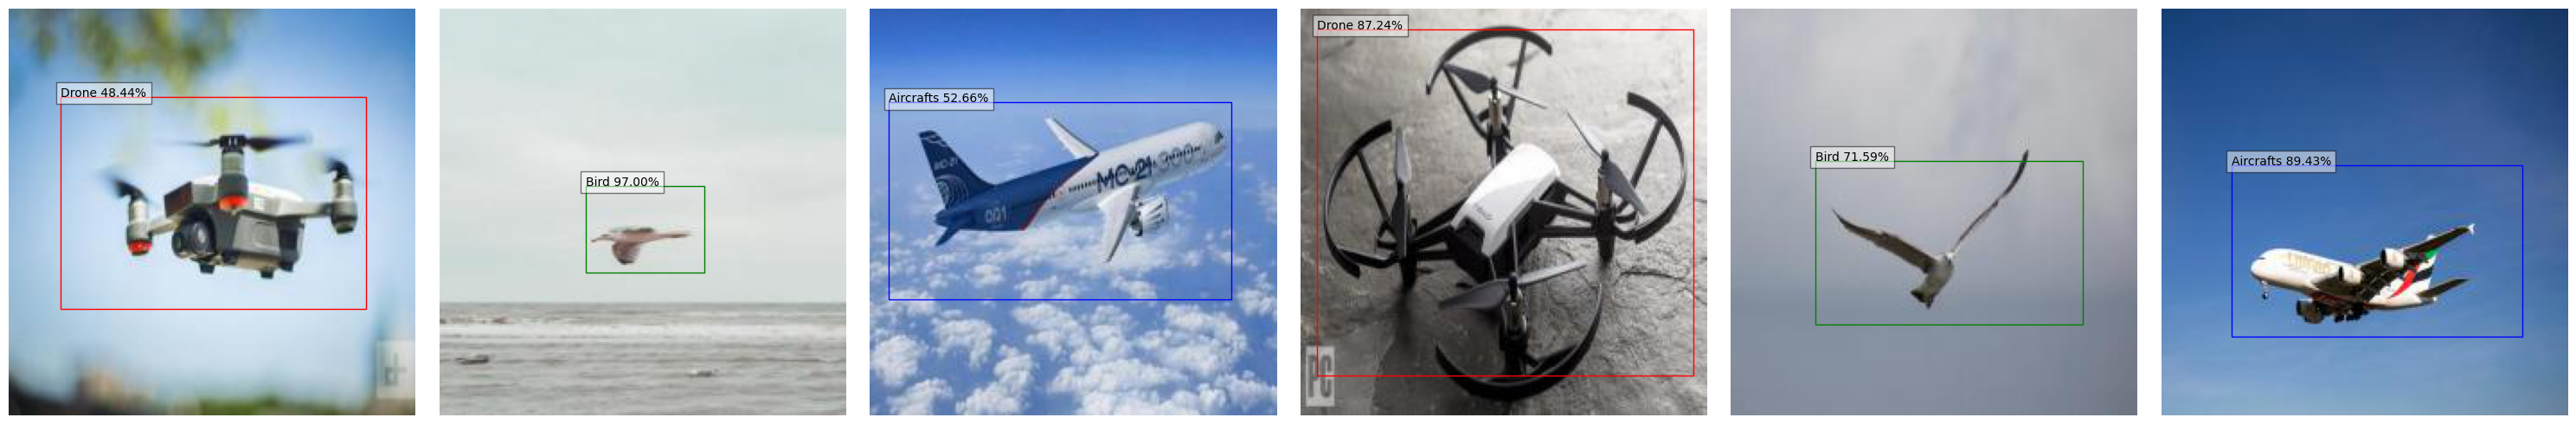

In [ ]:
# Object Detection on Test Images: We are coming to the end of the code.
# This code performs object detection on a set of test images. It loads the
# images, applies the trained model to predict the class and bounding box
# coordinates of the objects, and displays the images with the bounding boxes
# and predicted class labels.


import matplotlib.pyplot as plt
import matplotlib.patches as patches

# List of test image paths
test_image_paths = [
    "/content/drive/MyDrive/Dataset_of_900_photos/Photos/safe_drone-510-_jpg.rf.8e5b99e34efb0c321a3726b9476c0c43.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Photos/Bird-101-_jpg.rf.0f5d4764da4b2a2b000ed13547fc4b30.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Photos/Aircrafts-104-_jpg.rf.d21a7835fb9b60fa34bf1ce75e44381d.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Photos/safe_drone-374-_jpg.rf.4dff08214818a7a1cd2f589e409dacb3.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Photos/Bird-164-_jpg.rf.28b41e28809403f2ab26fb803a08a9c6.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Photos/Aircrafts-124-_jpg.rf.828ce3390a6ec2ca9d9aaf98fc021f81.jpg"
    # We can add more test image paths here
]

# Number of rows and columns in the subplot grid
num_rows = 1
num_cols = len(test_image_paths)

# Create a figure and axes for the subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(5*num_cols, 5))

# Define the class labels
class_labels = ["Drone", "Bird", "Aircrafts"]

for i, test_image_path in enumerate(test_image_paths):
    test_image = Image.open(test_image_path).convert('RGB')
    test_image_tensor = transform(test_image).unsqueeze(0).to(device)

    with torch.no_grad():  # Disable gradient calculation during inference
        model.eval()  # Set the model to evaluation mode
        predicted_classes, predicted_bbox = model(test_image_tensor)

    # Convert the predictions to human-readable labels
    _, predicted_class = torch.max(predicted_classes, 1)
    predicted_label = class_labels[predicted_class.item()]
    predicted_confidence = torch.softmax(predicted_classes, 1)[0][predicted_class].item()

    # Get the bounding box coordinates from the prediction
    predicted_bbox_coords = predicted_bbox.squeeze().cpu().numpy()
    xmin, ymin, width, height = predicted_bbox_coords
    xmax = xmin + width
    ymax = ymin + height

    # Set the color of the bounding box based on the class prediction
    if predicted_label == "Drone":
        box_color = 'red'
    elif predicted_label == "Bird":
        box_color = 'green'
    elif predicted_label == "Aircrafts":
        box_color = 'blue'

    # Display the test image with the bounding box, predicted class label, and confidence score
    ax = axes[i] if num_cols > 1 else axes
    ax.imshow(test_image)
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=1, edgecolor=box_color, facecolor='none')
    ax.add_patch(rect)
    ax.text(xmin, ymin, f"{predicted_label} {predicted_confidence*100:.2f}%", bbox=dict(facecolor='white', alpha=0.5))
    ax.axis('off')

    print(f"Predicted bounding box coordinates: {predicted_bbox_coords}")
    print(f"Predicted class: {predicted_label}")
    print(f"Confidence: {predicted_confidence*100:.2f}%")

plt.tight_layout()
plt.show()


Again, let's go through the code step by step:

```python
import matplotlib.pyplot as plt
import matplotlib.patches as patches
```
- These lines import the necessary libraries for displaying images and drawing bounding boxes on images using matplotlib.

```python
# List of test image paths
test_image_paths = [
    # List of file paths to the test images
    # We have six test images in this example, but more can be added
]
```
- This defines a list `test_image_paths` that contains file paths to the test images on which we want to perform object detection.

```python
# Number of rows and columns in the subplot grid
num_rows = 1
num_cols = len(test_image_paths)
```
- These variables `num_rows` and `num_cols` are used to define the size of the subplot grid that will display the test images and their predicted bounding boxes.

```python
# Create a figure and axes for the subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(5*num_cols, 5))
```
- This creates a grid of subplots using matplotlib to display the test images with their bounding boxes and predicted class labels.

```python
# Define the class labels
class_labels = ["Drone", "Bird", "Aircrafts"]
```
- This list `class_labels` contains the names of the classes that the model can predict. In this example, the model can predict three classes: "Drone", "Bird", and "Aircrafts".

```python
for i, test_image_path in enumerate(test_image_paths):
    test_image = Image.open(test_image_path).convert('RGB')
    test_image_tensor = transform(test_image).unsqueeze(0).to(device)
```
- This loop iterates over each test image path in the `test_image_paths` list.
- It opens each test image using `PIL.Image.open()` and converts it to RGB format using `.convert('RGB')`.
- The image is then transformed using the `transform` composed earlier to resize, normalize, and convert it to a tensor.
- The transformed image is converted to a tensor and moved to the device (GPU) using `.to(device)`.

```python
with torch.no_grad():  # Disable gradient calculation during inference
    model.eval()  # Set the model to evaluation mode
    predicted_classes, predicted_bbox = model(test_image_tensor)
```
- This part performs inference on the test image using the trained `model`.
- The model is set to evaluation mode using `model.eval()` to disable features like dropout during inference.
- The test image tensor is passed through the model to obtain the predicted class labels (`predicted_classes`) and bounding box coordinates (`predicted_bbox`) for the objects in the image.

```python
# Convert the predictions to human-readable labels
_, predicted_class = torch.max(predicted_classes, 1)
predicted_label = class_labels[predicted_class.item()]
predicted_confidence = torch.softmax(predicted_classes, 1)[0][predicted_class].item()
```
- The predicted class label and its confidence score are extracted from the `predicted_classes`.
- The `torch.max` function is used to find the index of the class with the highest score in the `predicted_classes`.
- The predicted class label is obtained from `class_labels` using the index.
- The confidence score is computed using the softmax function to convert the model's output scores into probabilities.

```python
# Get the bounding box coordinates from the prediction
predicted_bbox_coords = predicted_bbox.squeeze().cpu().numpy()
xmin, ymin, width, height = predicted_bbox_coords
xmax = xmin + width
ymax = ymin + height
```
- The bounding box coordinates are obtained from `predicted_bbox`.
- The `predicted_bbox` tensor is first squeezed to remove any dimensions with size 1, then converted to a NumPy array and moved to the CPU using `.cpu().numpy()`.
- The bounding box coordinates (xmin, ymin, width, height) are extracted from the NumPy array.

```python
# Set the color of the bounding box based on the class prediction
if predicted_label == "Drone":
    box_color = 'red'
elif predicted_label == "Bird":
    box_color = 'green'
elif predicted_label == "Aircrafts":
    box_color = 'blue'
```
- Based on the predicted class label, a color is assigned to the bounding box. The colors used here are red for "Drone," green for "Bird," and blue for "Aircrafts."

```python
# Display the test image with the bounding box, predicted class label, and confidence score
ax = axes[i] if num_cols > 1 else axes
ax.imshow(test_image)
rect = patches.Rectangle((xmin, ymin), width, height, linewidth=1, edgecolor=box_color, facecolor='none')
ax.add_patch(rect)
ax.text(xmin, ymin, f"{predicted_label} {predicted_confidence*100:.2f}%", bbox=dict(facecolor='white', alpha=0.5))
ax.axis('off')
```
- This part displays the test image along with the predicted bounding box, class label, and confidence score.
- The bounding box is drawn using `matplotlib.patches.Rectangle`, with coordinates obtained earlier and using the assigned `box_color`.
- The predicted class label and confidence score are displayed as text on top of the bounding box.
- `ax.axis('off')` is used to remove the axis ticks and labels from the subplot.

```python
print(f"Predicted bounding box coordinates: {predicted_bbox_coords}")
print(f"Predicted class: {predicted_label}")
print(f"Confidence: {predicted_confidence*100:.2f}%")
```
- The above lines simply print the predicted bounding box coordinates, predicted class label, and confidence score for each test image.

```python
plt.tight_layout()
plt.show()
```
- This adjusts the layout of the subplots and displays the figure with the test images and their bounding boxes.

#Predicting class with bounding box on new images for testing

Predicted bounding box coordinates: [ 11.3554125  64.221794  210.19618   114.37269  ]
Predicted class: Aircrafts
Confidence: 0.87
Predicted bounding box coordinates: [ 62.68143  77.09978 115.3253   95.75607]
Predicted class: Bird
Confidence: 0.90
Predicted bounding box coordinates: [ 13.695892  34.218636 196.92258  150.72466 ]
Predicted class: Drone
Confidence: 0.44
Predicted bounding box coordinates: [  9.520756  64.47641  211.3142   108.451416]
Predicted class: Aircrafts
Confidence: 0.85
Predicted bounding box coordinates: [ 88.81678   61.144985 105.52123  115.0309  ]
Predicted class: Bird
Confidence: 0.82
Predicted bounding box coordinates: [ 10.646399  66.73333  193.68803   89.31227 ]
Predicted class: Drone
Confidence: 0.63


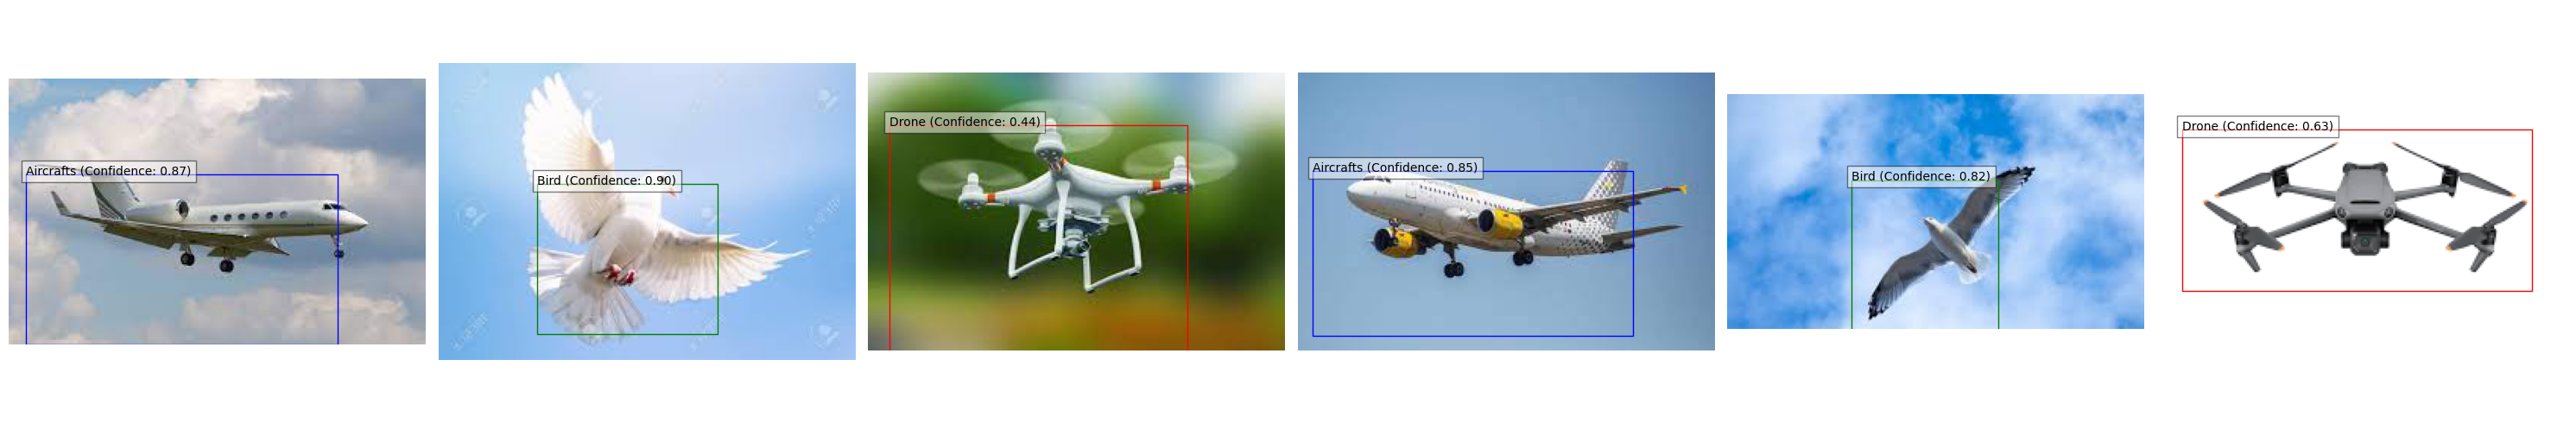

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# List of test image paths
test_image_paths = [
    "/content/drive/MyDrive/Dataset_of_900_photos/Testing images/Aircraft test 1.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Testing images/Bird test 1.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Testing images/Drone test 1.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Testing images/Aircraft test 2.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Testing images/Bird test 2.jpg",
    "/content/drive/MyDrive/Dataset_of_900_photos/Testing images/Drone test 2.jpg",
]

# Number of rows and columns in the subplot grid
num_rows = 1
num_cols = len(test_image_paths)

# Create a figure and axes for the subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(5*num_cols, 5))

for i, test_image_path in enumerate(test_image_paths):
    test_image = Image.open(test_image_path).convert('RGB')
    test_image_tensor = transform(test_image).unsqueeze(0).to(device)

    with torch.no_grad():  # Disable gradient calculation during inference
        model.eval()  # Set the model to evaluation mode
        predicted_classes, predicted_bbox = model(test_image_tensor)

    # Convert the predictions to human-readable labels
    _, predicted_class = torch.max(predicted_classes, 1)
    label_dict_reverse = {v: k for k, v in dataset.label_dict.items()}
    predicted_label = label_dict_reverse[predicted_class.item()]
    predicted_confidence = torch.softmax(predicted_classes, 1)[0][predicted_class].item()

    # Get the bounding box coordinates from the prediction
    predicted_bbox_coords = predicted_bbox.squeeze().cpu().numpy()
    xmin, ymin, width, height = predicted_bbox_coords
    xmax = xmin + width
    ymax = ymin + height

    # Set the color of the bounding box based on the class prediction
    if predicted_label == "Drone":
        box_color = 'red'
    elif predicted_label == "Bird":
        box_color = 'green'
    elif predicted_label == "Aircrafts":
        box_color = 'blue'

    # Display the test image with the bounding box, predicted class label, and confidence score
    ax = axes[i] if num_cols > 1 else axes
    ax.imshow(test_image)
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=1, edgecolor=box_color, facecolor='none')
    ax.add_patch(rect)
    ax.text(xmin, ymin, f"{predicted_label} (Confidence: {predicted_confidence:.2f})", bbox=dict(facecolor='white', alpha=0.5))
    ax.axis('off')

    print(f"Predicted bounding box coordinates: {predicted_bbox_coords}")
    print(f"Predicted class: {predicted_label}")
    print(f"Confidence: {predicted_confidence:.2f}")

plt.tight_layout()
plt.show()


Same code, just the links are different. This part will show how well our model performs on new images.

#This is the complete code with line by line explanation. Now you can proceed with this code and make the software part.